# 01 · Dataset Quality & Exploratory Data Analysis
Fashion-MNIST (Xiao et al., 2017): 70,000 28×28 grayscale clothing images, 10 classes.

Every plot is produced by `src/eda.py`; this notebook narrates the findings.

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Image, display
from src.config import *
from src.data_loader import load_raw, to_unit, make_splits
from src.plotting import set_style
set_style()
def show(name, w=900): display(Image(filename=str(FIG_DIR / f'{name}.png'), width=w))

## 1. Load & audit
IDX files are read directly (`src/data_loader.py`). We check shape, value range, missing values, blank images, exact duplicates and train/test leakage.

In [2]:
Xtr_u8, ytr, Xte_u8, yte = load_raw()
from src import eda
eda.quality_report(Xtr_u8, ytr, Xte_u8, yte)

,check,value
0,train_shape,"(60000, 28, 28)"
1,test_shape,"(10000, 28, 28)"
2,dtype,uint8
3,pixel_min,0
4,pixel_max,255
5,missing_values,0
6,n_classes,10
7,blank_images_train,0
8,exact_duplicates_in_train,0
9,train_test_overlap,0


**Finding:** the data is clean - no missing/blank/duplicate images and zero train-test overlap. The only preprocessing step is scaling to [0,1].

## 2. Class balance

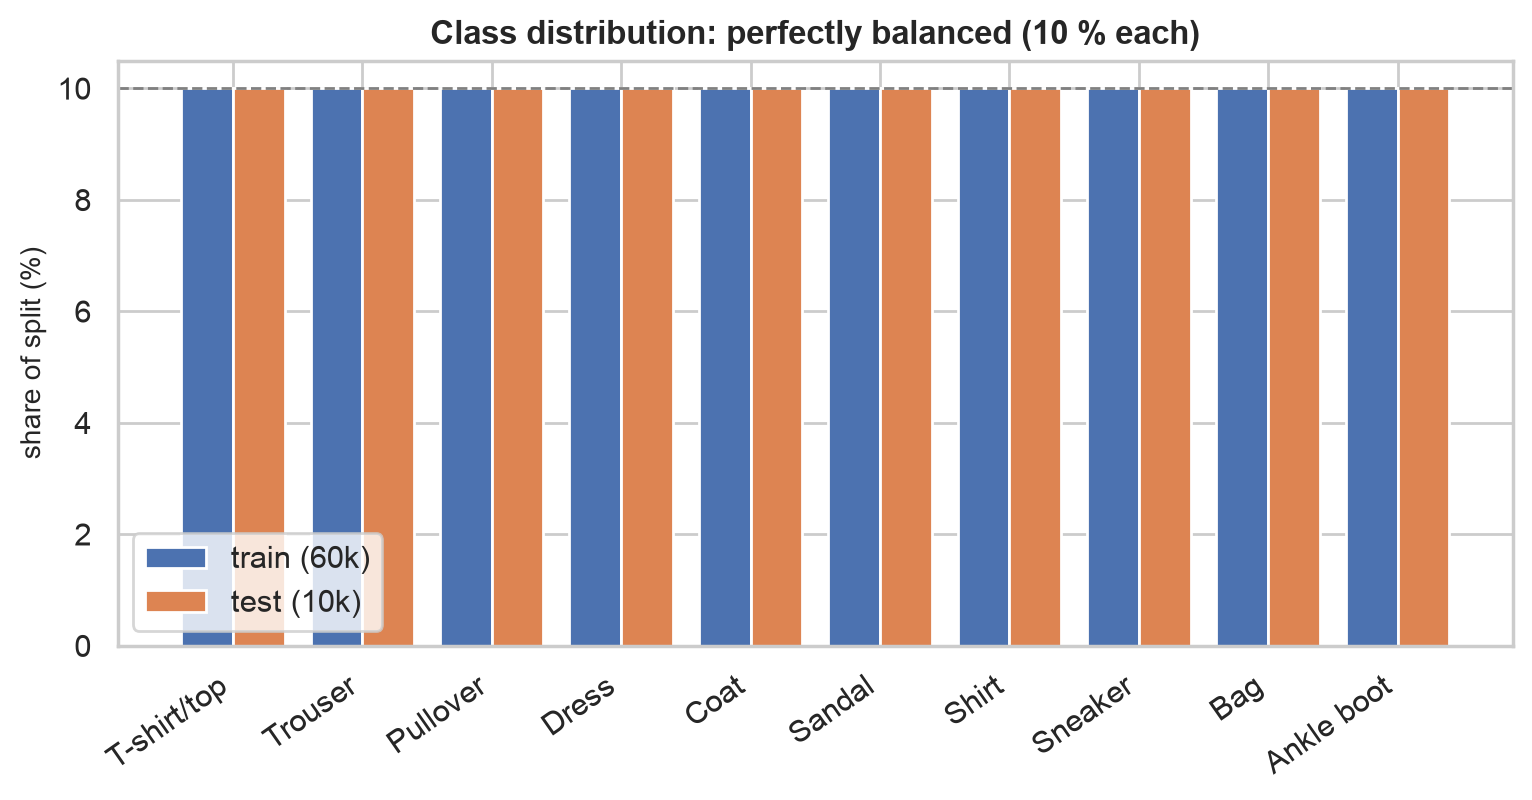

,class,train,test,train_%,test_%
0,T-shirt/top,6000,1000,10.0,10.0
1,Trouser,6000,1000,10.0,10.0
2,Pullover,6000,1000,10.0,10.0
3,Dress,6000,1000,10.0,10.0
4,Coat,6000,1000,10.0,10.0
5,Sandal,6000,1000,10.0,10.0
6,Shirt,6000,1000,10.0,10.0
7,Sneaker,6000,1000,10.0,10.0
8,Bag,6000,1000,10.0,10.0
9,Ankle boot,6000,1000,10.0,10.0


In [3]:
show('eda_01_class_distribution', 700); pd.read_csv(TABLE_DIR/'eda_class_distribution.csv')

Perfectly balanced (6,000 / 1,000 per class) -> accuracy is a valid headline metric, but we still report macro-F1 and per-class recall.

## 3. What do the images look like?

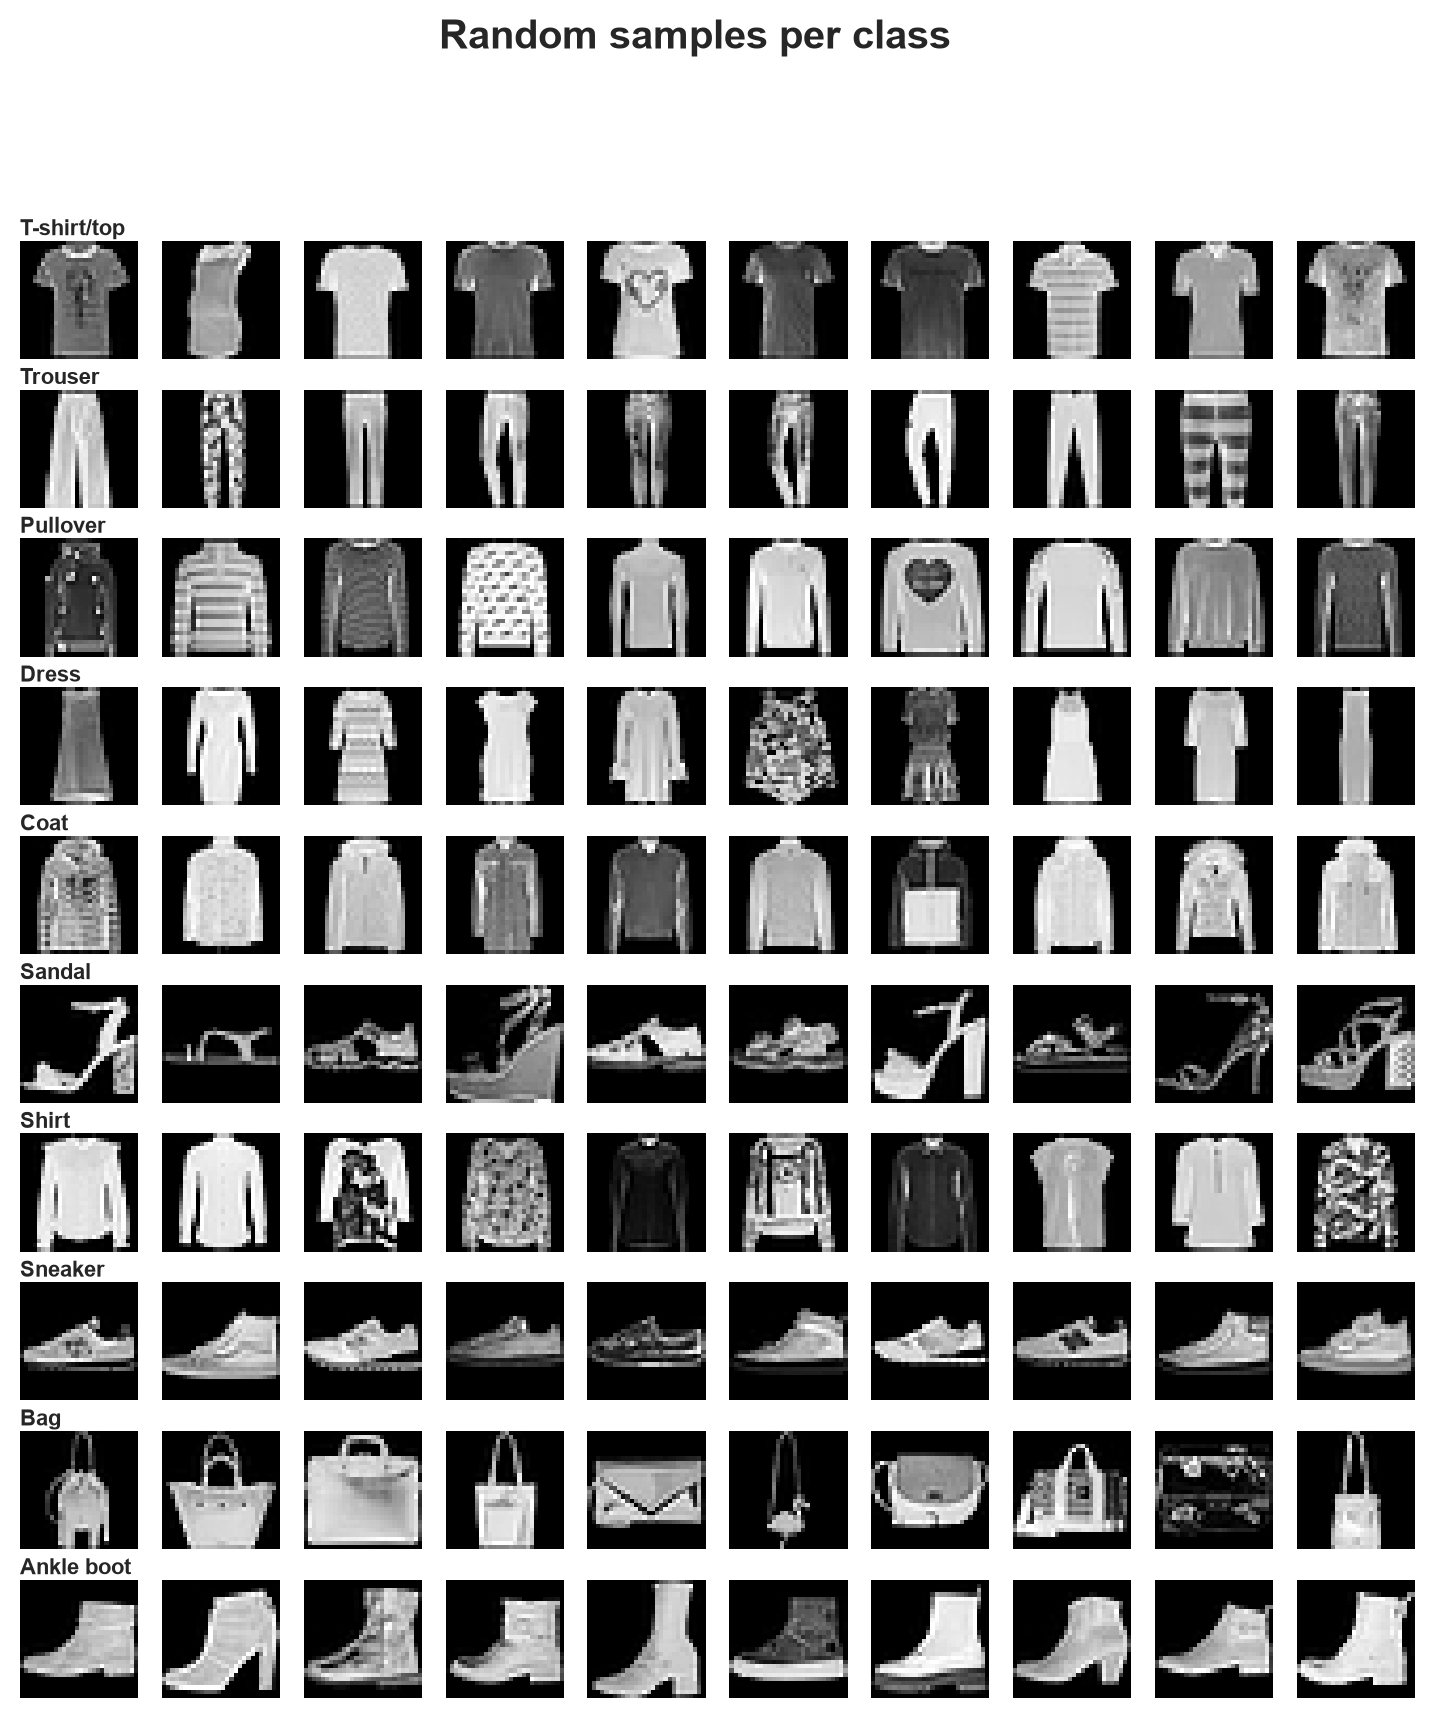

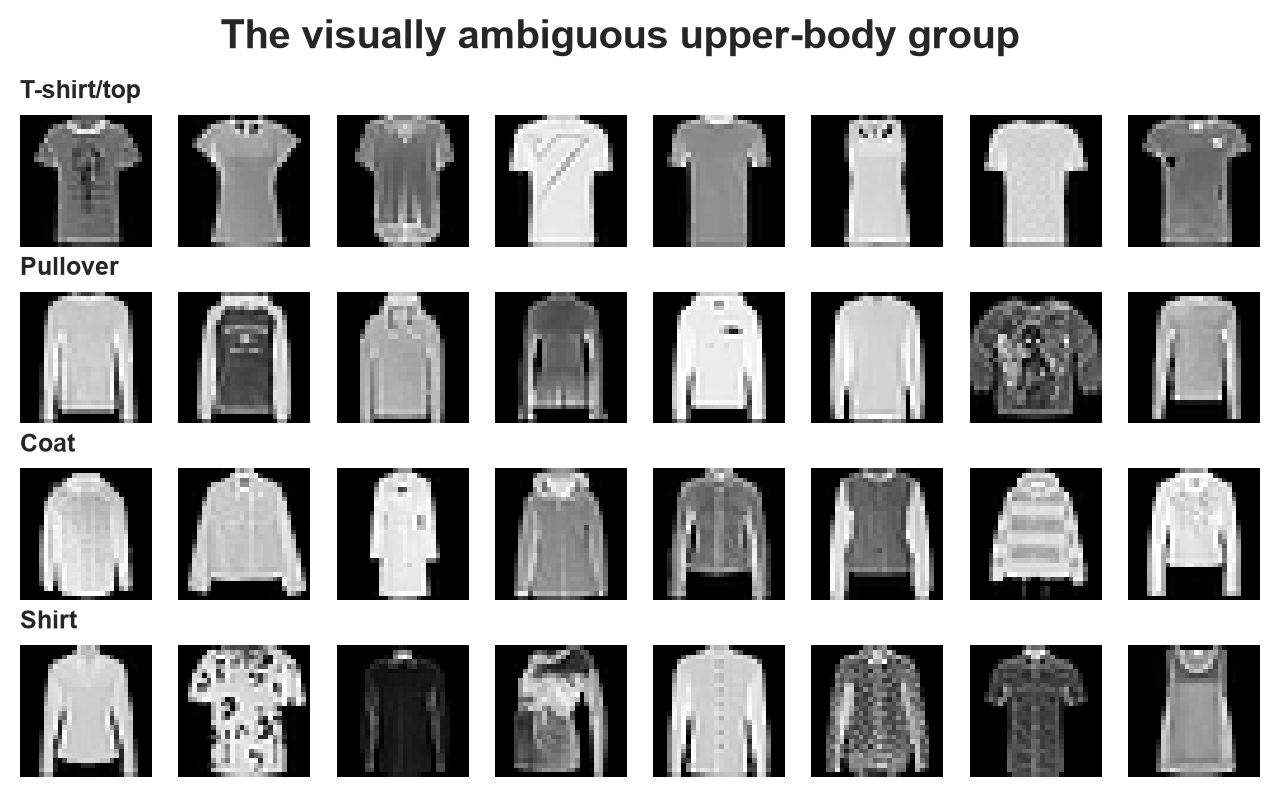

In [4]:
show('eda_02_sample_grid', 650); show('eda_12_ambiguous_group', 650)

The four upper-body classes (T-shirt/top, Pullover, Coat, Shirt) are visually near-identical silhouettes -> expected hard group.

## 4. Class means, intensity and shape statistics

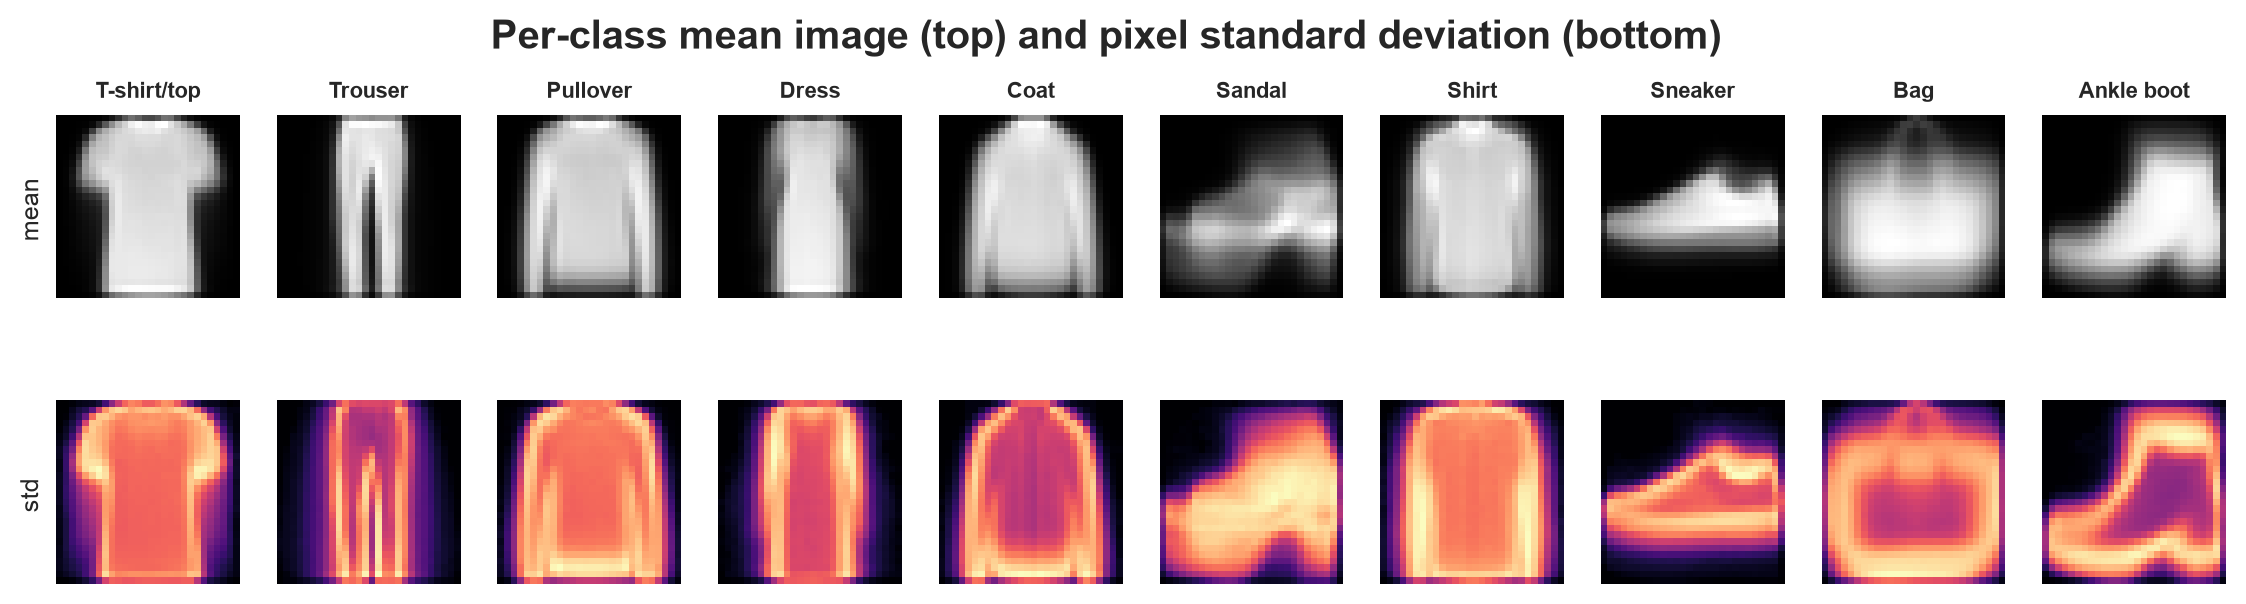

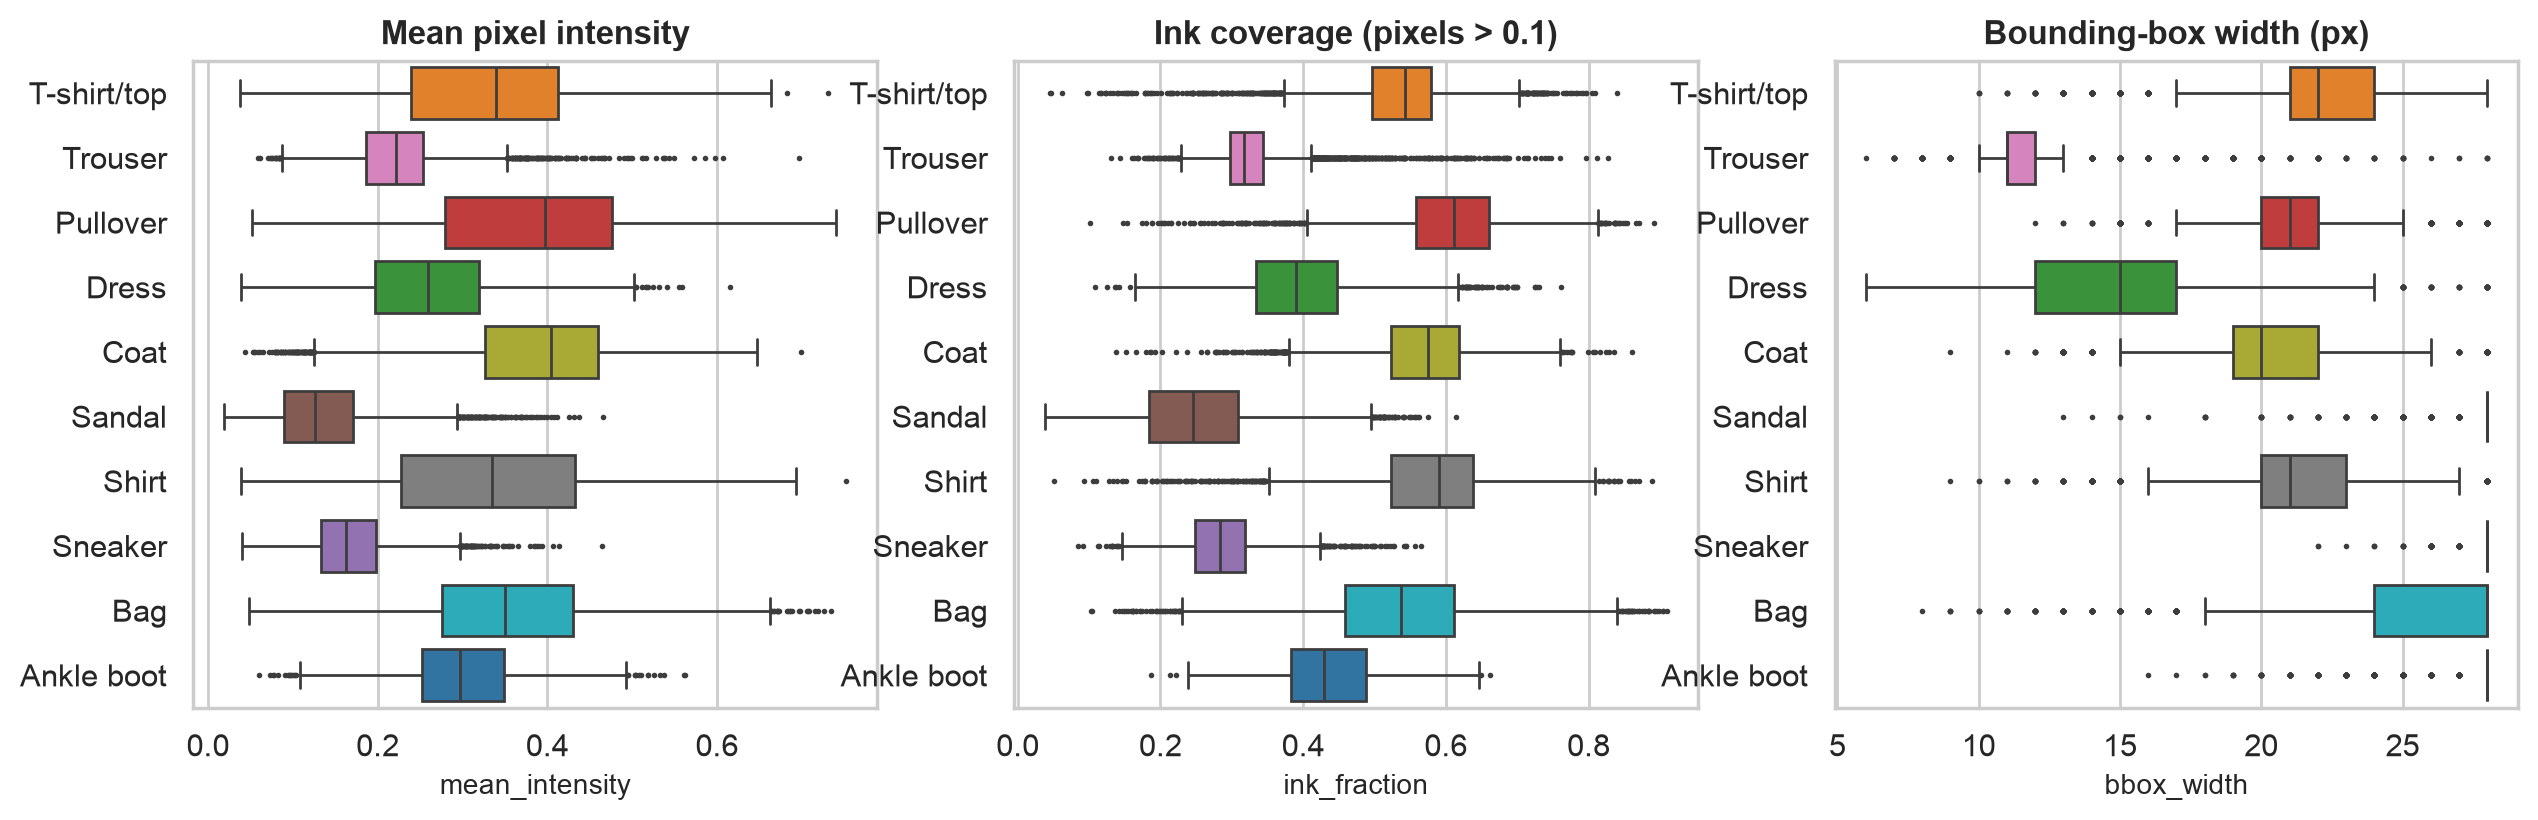

,mean_intensity_mean,mean_intensity_std,ink_fraction_mean,ink_fraction_std,bbox_height_mean,bbox_height_std,bbox_width_mean,bbox_width_std
class,,,,,,,,
T-shirt/top,0.326,0.113,0.533,0.082,27.746,1.080,21.741,3.156
Trouser,0.223,0.057,0.331,0.064,27.946,0.261,11.676,2.049
Pullover,0.377,0.128,0.608,0.084,27.793,0.632,21.207,2.097
Dress,0.259,0.084,0.393,0.087,27.898,0.504,14.683,3.352
Coat,0.385,0.104,0.565,0.079,27.822,0.549,20.106,2.471
Sandal,0.137,0.062,0.253,0.089,16.128,6.172,27.812,0.847
Shirt,0.332,0.130,0.578,0.093,27.709,0.956,21.463,2.911
Sneaker,0.168,0.050,0.287,0.055,13.406,2.631,27.854,0.406
Bag,0.354,0.113,0.535,0.118,23.343,4.858,25.564,3.716


In [5]:
show('eda_03_mean_std_images'); show('eda_04_intensity_shape_boxplots'); pd.read_csv(TABLE_DIR/'eda_class_summary_stats.csv', index_col=0)

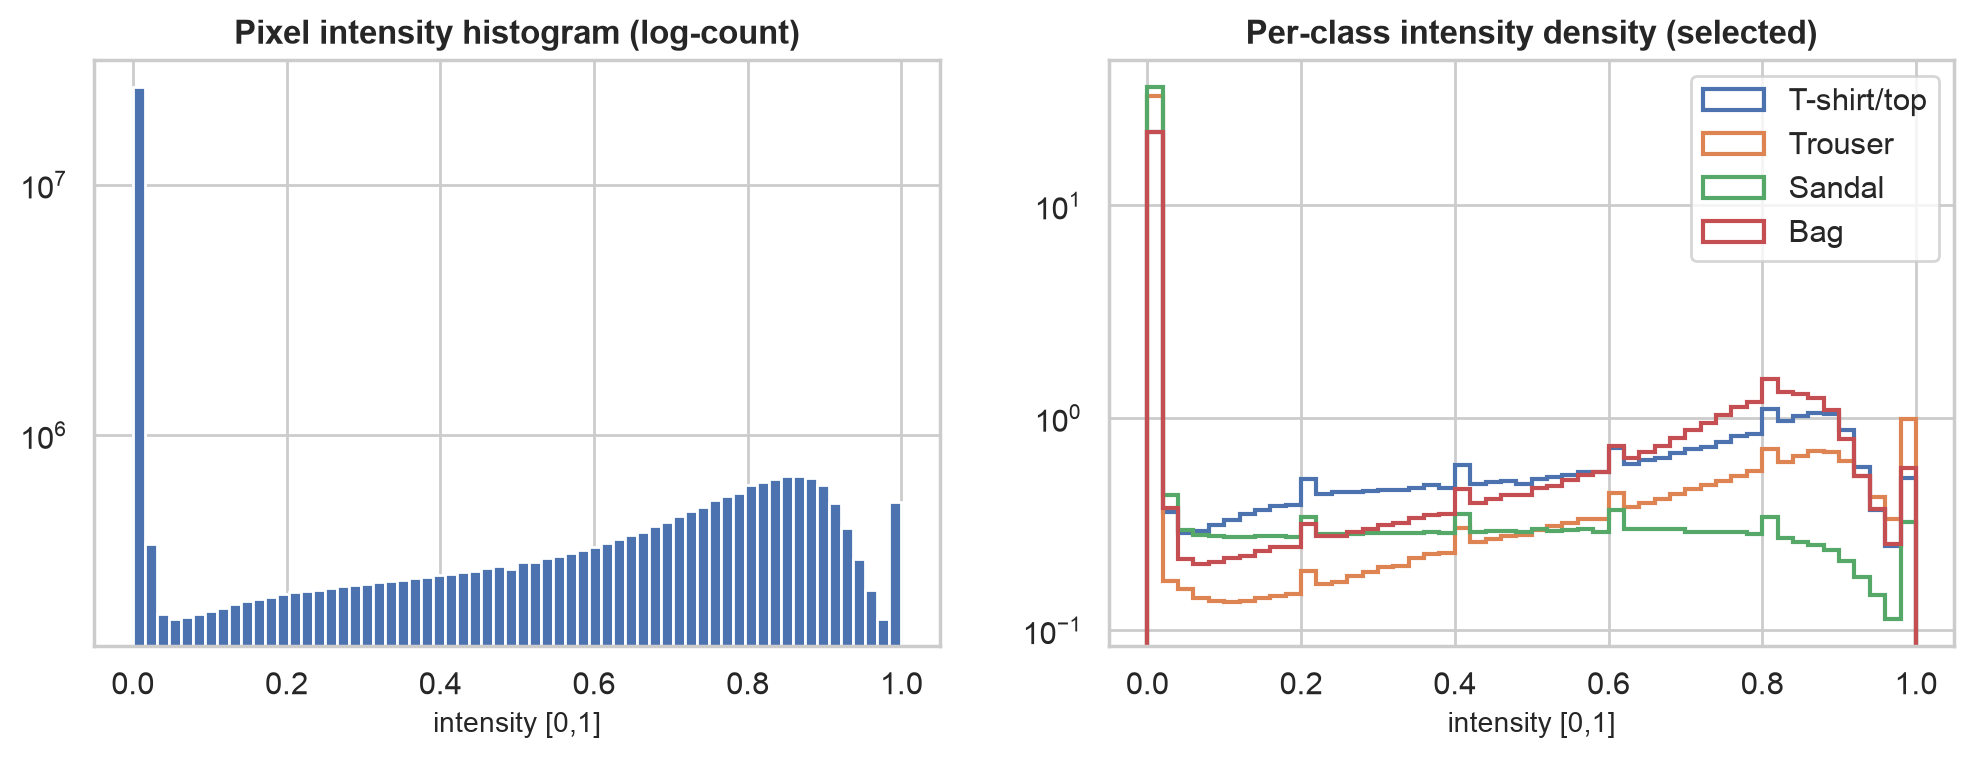

In [6]:
show('eda_05_pixel_histogram')

About 50 % of pixels are exactly zero (background): the data is sparse. Footwear has small height / large width; trousers are narrow; bags have the widest variance in size.

## 5. Which pixels matter?

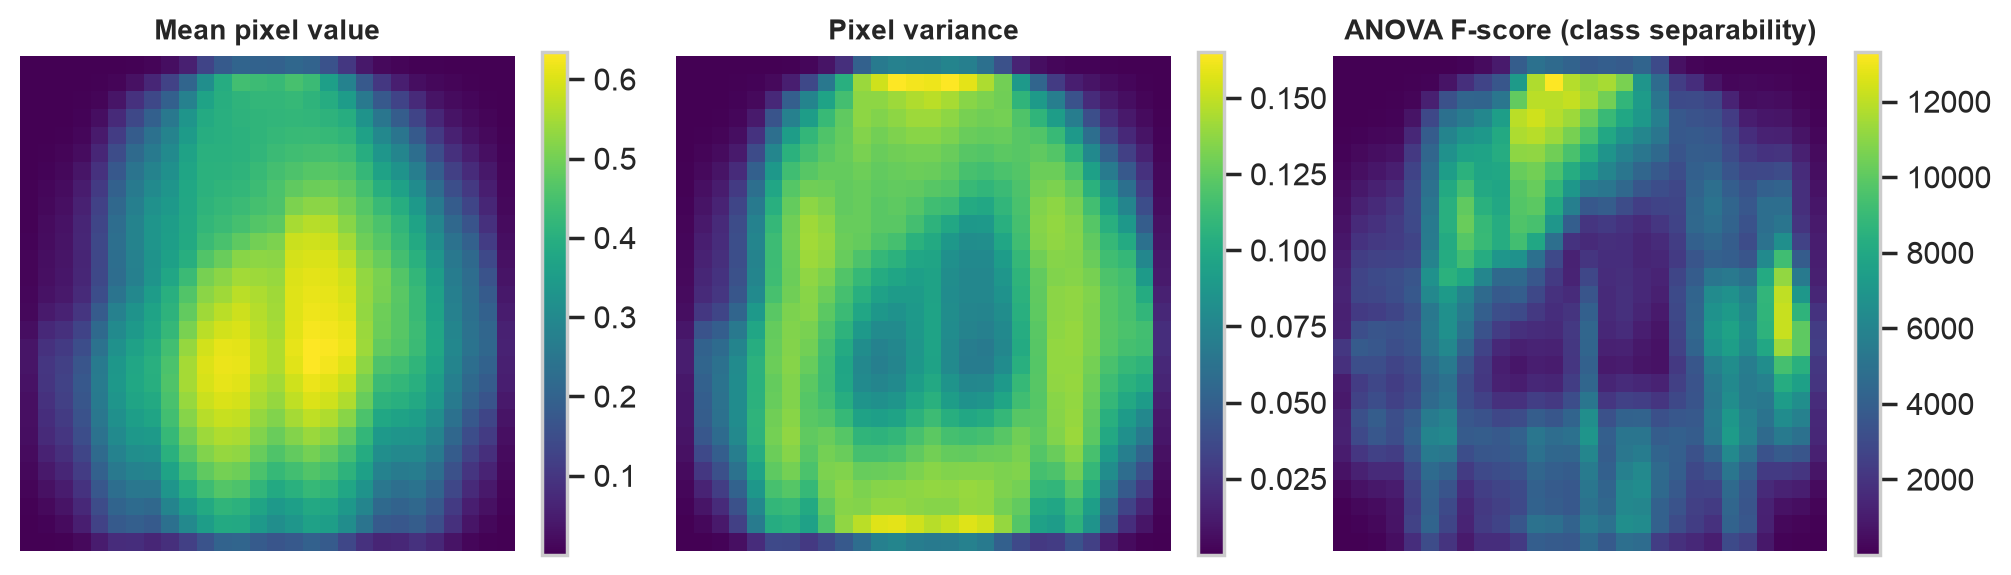

In [7]:
show('eda_06_pixel_variance_fscore', 1000)

The border pixels have ~zero variance and ~zero F-score: they carry no information. Discriminative pixels lie at the centre and along the silhouette edges.

## 6. Is there spatial structure that flattening destroys?

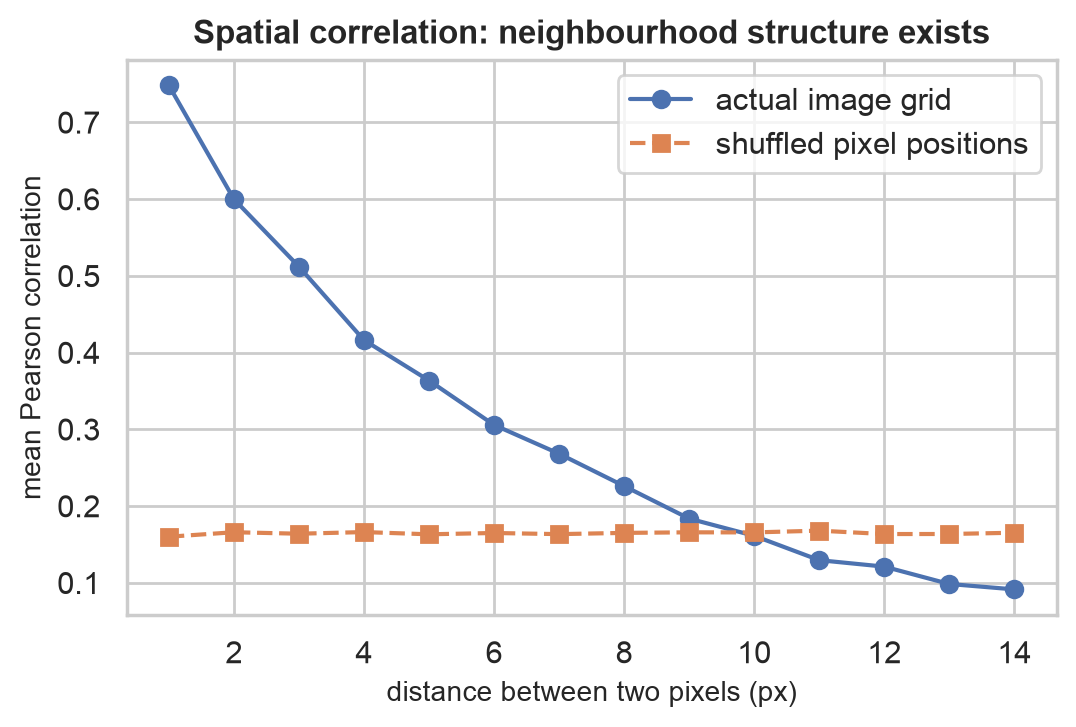

,class_a,class_b,mean_image_distance
0,Pullover,Coat,2.482678
1,Pullover,Shirt,2.675163
2,Coat,Shirt,3.023170
3,T-shirt/top,Shirt,3.716013
4,Sandal,Sneaker,3.838488
5,Trouser,Dress,4.099473
6,T-shirt/top,Dress,4.509928
7,Dress,Shirt,5.299816


In [8]:
show('eda_07_spatial_correlation', 600); pd.read_csv(TABLE_DIR/'eda_class_pair_distance.csv').head(8)

Adjacent pixels correlate at r≈0.75, far above the shuffled null (≈0.16). Flattening treats pixel 5 and pixel 6 like any two unrelated pixels, which is the motivation for neighbourhood-based descriptors (HOG).

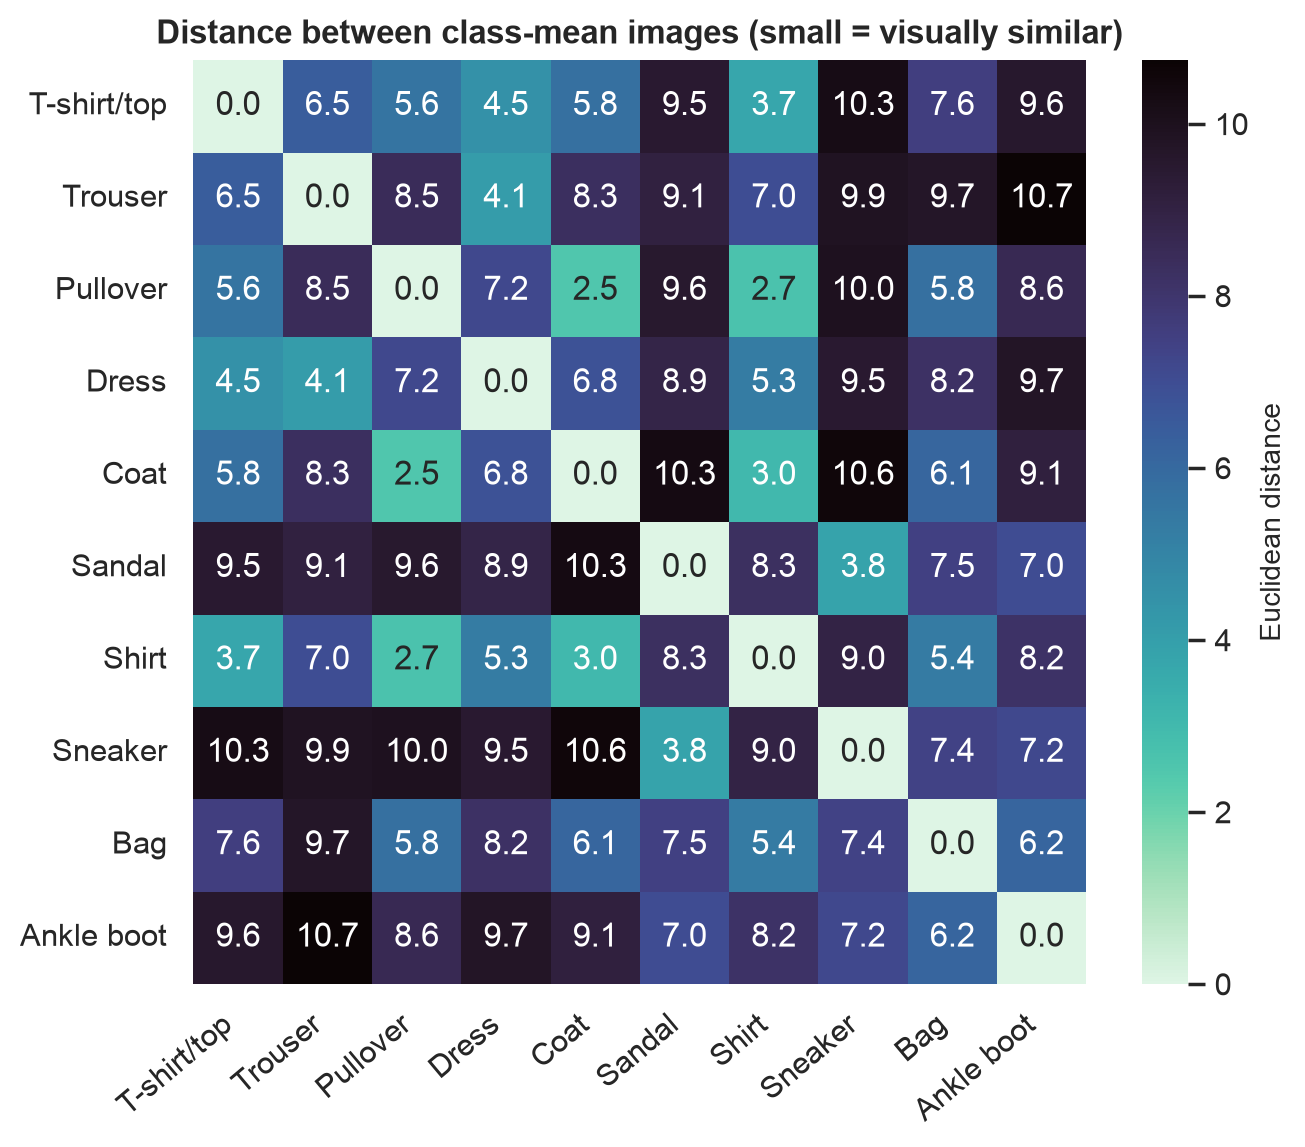

In [9]:
show('eda_08_class_mean_distance', 650)

Mean-image distances predict the confusion structure: **Pullover-Coat-Shirt-T-shirt** are the closest pairs.

## 7. Intrinsic dimensionality & embeddings

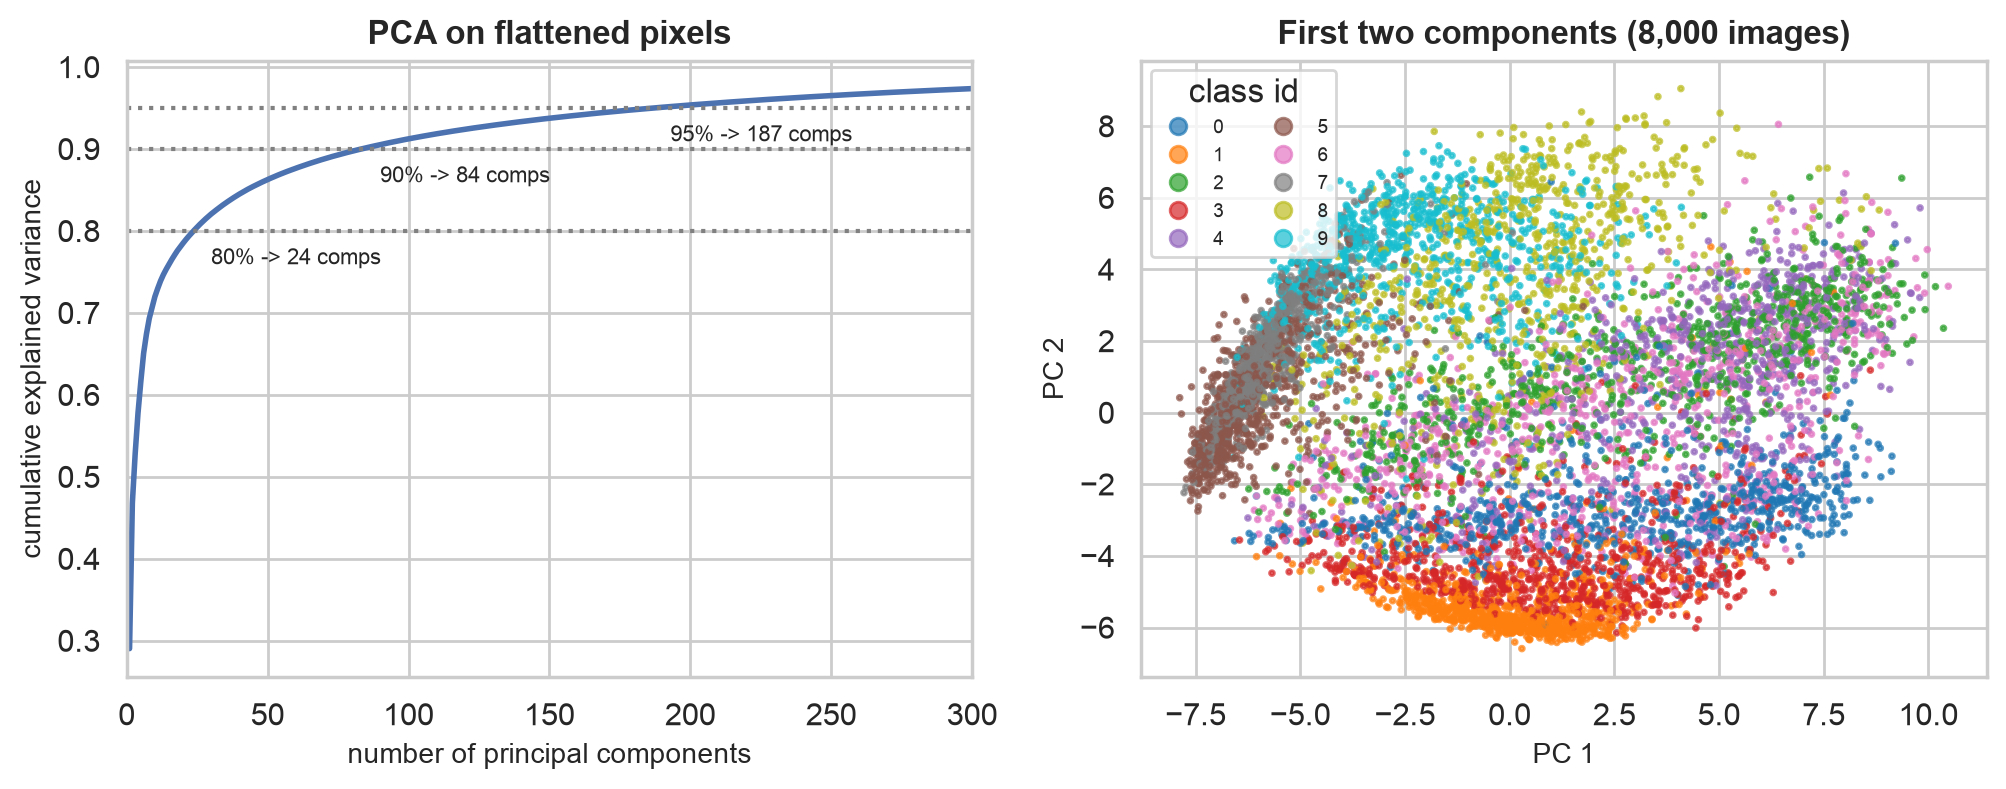

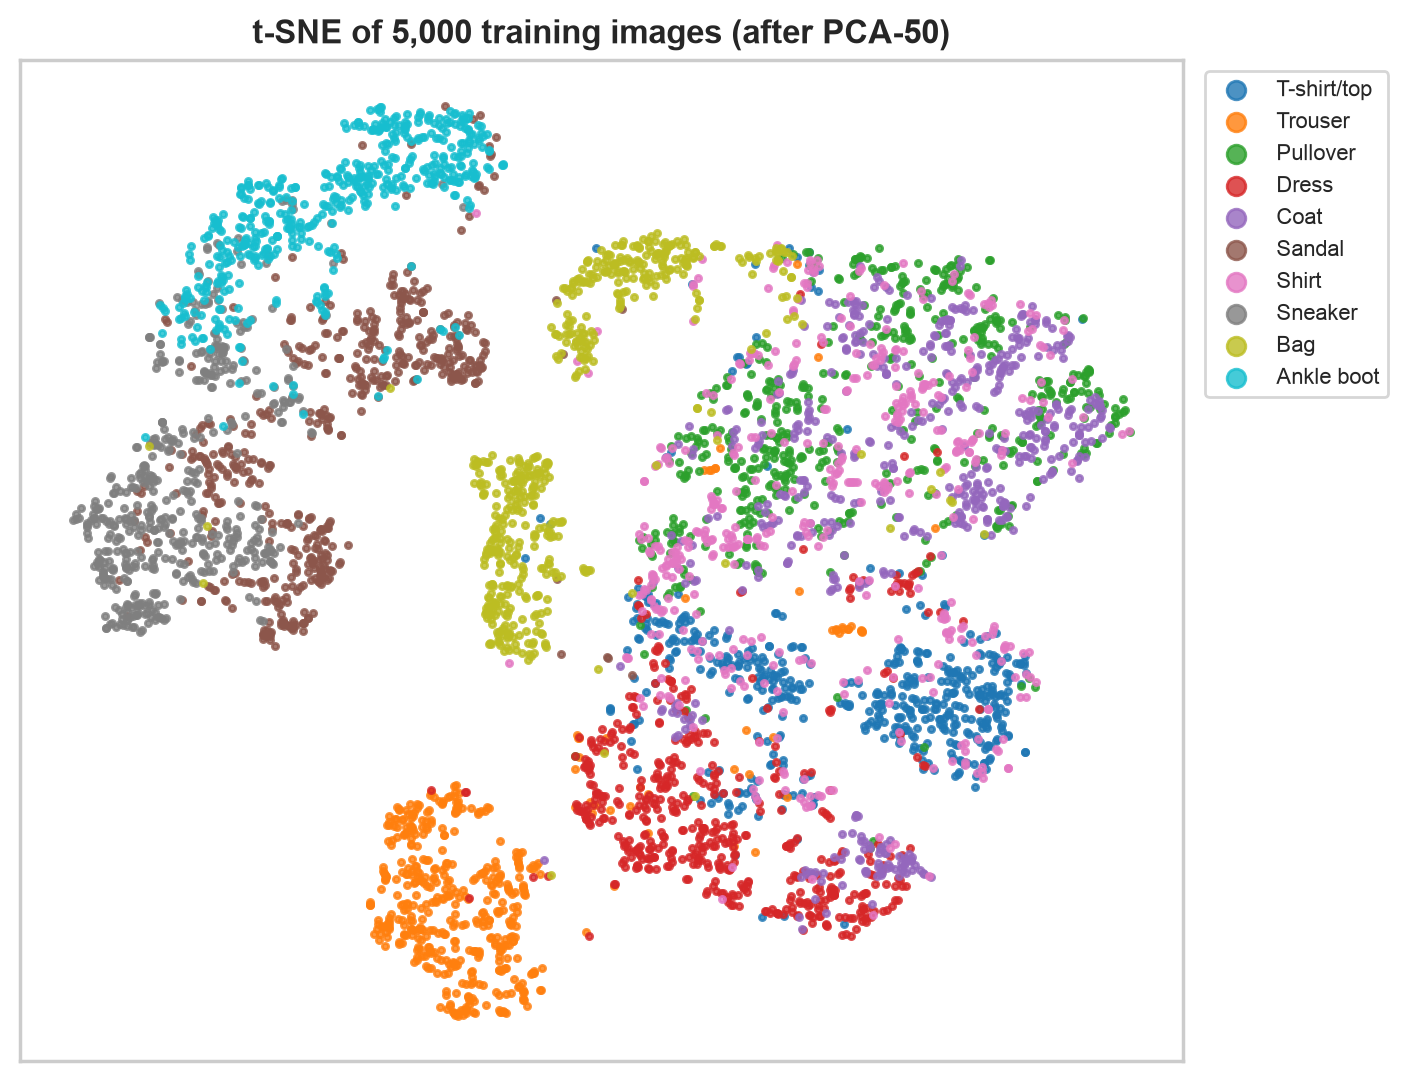

,variance_target,n_components
0,0.80,24
1,0.90,84
2,0.95,187


In [10]:
show('eda_09_pca'); show('eda_10_tsne', 650); pd.read_csv(TABLE_DIR/'eda_pca_components.csv')

24 principal components explain 80 % and 187 explain 95 % of the variance (of 784) -> strong redundancy. t-SNE shows footwear, trousers and bags as clean clusters while the upper-body classes overlap.

## 8. Train/test shift & orientation

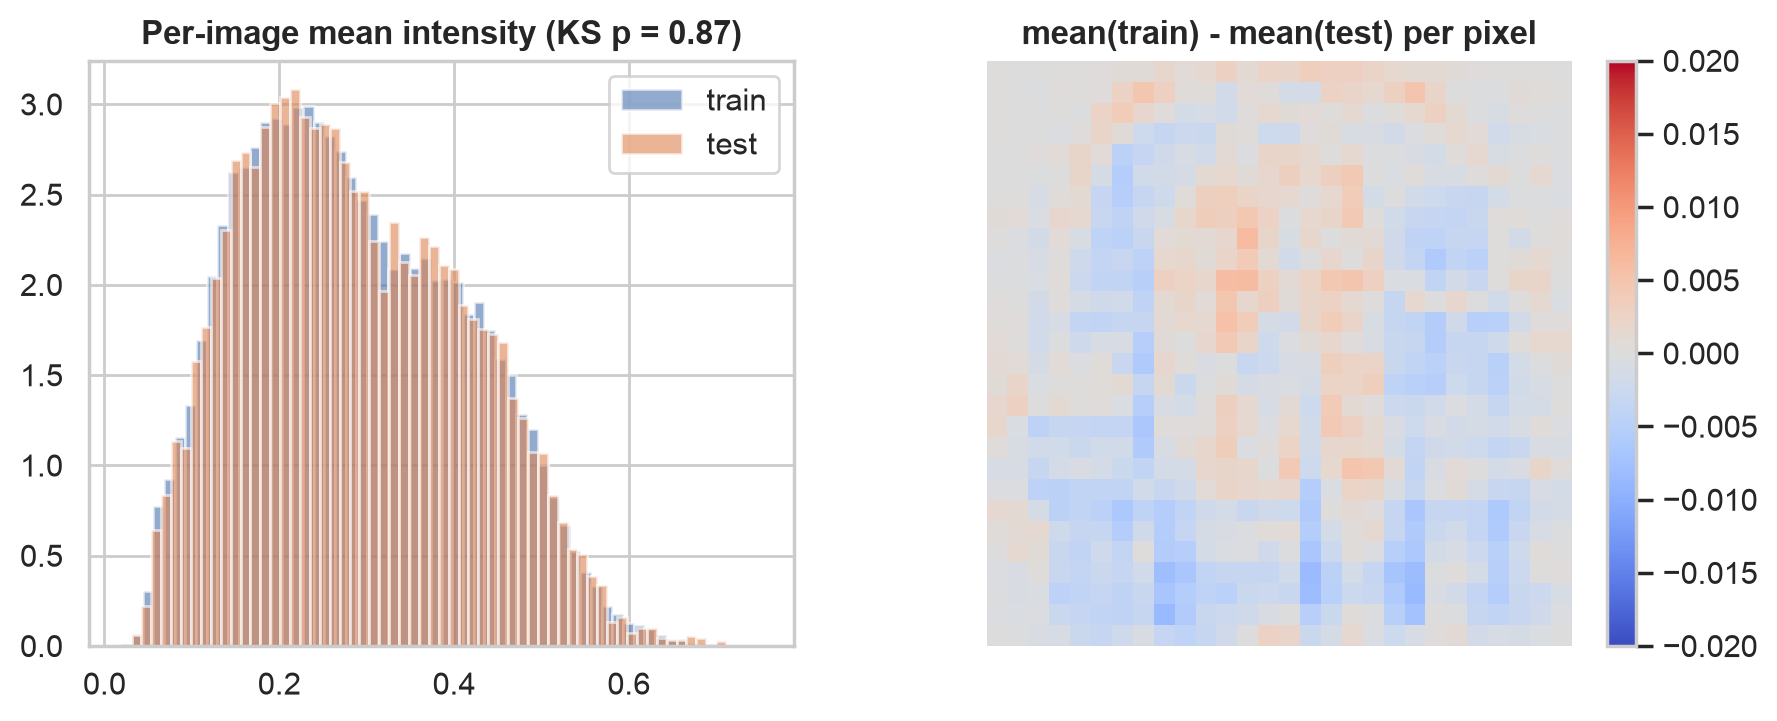

,top_minus_bottom_share
class,
T-shirt/top,0.081
Trouser,0.145
Pullover,-0.019
Dress,-0.070
Coat,-0.054
Sandal,-0.354
Shirt,-0.026
Sneaker,-0.309
Bag,-0.305


In [11]:
show('eda_11_train_test_shift', 800); pd.read_csv(TABLE_DIR/'eda_orientation_check.csv', index_col=0)

KS test: no shift between train and test. Images are upright (footwear/bags heavier at the bottom, tops/trousers heavier at the top), so HOG can be computed directly without rotating.

### EDA conclusions
1. Clean, balanced data; no cleaning required.
2. Strong spatial structure + sparsity -> neighbourhood descriptors are justified.
3. Upper-body group is the predicted difficulty.
4. Heavy pixel redundancy -> PCA/HOG compress without losing the class signal.